In [ ]:
# -*- coding: utf-8 -*-
"""
Sentinel-2 GEE 稳健下载与合并（含断点续跑 / 5分钟桶最优影像）
- 单窗口（start_date ~ end_date）内：对影像逐一下载所选波段（可分块），合并为多波段 TIFF
- 断点续跑：每个窗口目录下的 checkpoint.json 持久化 processed / daily_candidates
- 稳健性：最小化 getInfo 次数（aggregate_array），分页兜底；requests.Session + Retry；下载后用 rasterio 校验
- 5 分钟时间桶：同一桶仅保留有效像元比例更高的那张（其余自动丢弃）
"""

import os
import sys
import time
import json
import glob
import random
import shutil
import logging
from datetime import datetime

import pandas as pd
import numpy as np
import rasterio
from rasterio.merge import merge as rio_merge
from rasterio.warp import calculate_default_transform, reproject, Resampling

import ee
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

# ====================== 参数与全局常量 ======================
MAX_RETRIES = 5
TIMEOUT_SEC = 180
MISSING_THRESH = 0.40
BUCKET_MINUTES = 5

# 必要：初始化 GEE（你已有的工程）
ee.Initialize(project='singular-tuner-471501-g3')

# ====================== Tee: 同时写 log 与控制台 ======================
class Tee:
    def __init__(self, file):
        self.file = file
        self.stdout = sys.stdout
    def write(self, data):
        self.file.write(data)
        self.stdout.write(data)
    def flush(self):
        self.file.flush()
        self.stdout.flush()

# ====================== 工具函数 ======================
def cleanup_path(path):
    """安全删除文件/文件夹"""
    try:
        if os.path.isdir(path):
            shutil.rmtree(path, ignore_errors=True)
        elif os.path.isfile(path):
            os.remove(path)
    except:
        pass

def split_roi(roi, nx=2, ny=2):
    """把 ROI 划分成 nx * ny 个小块"""
    coords = roi.bounds().coordinates().getInfo()[0]
    minx, miny = coords[0]
    maxx, maxy = coords[2]
    dx = (maxx - minx) / nx
    dy = (maxy - miny) / ny
    rois = []
    for i in range(nx):
        for j in range(ny):
            rois.append(ee.Geometry.Rectangle([
                minx + i*dx, miny + j*dy,
                minx + (i+1)*dx, miny + (j+1)*dy
            ]))
    return rois

def floor_to_bucket_5min(date_str):
    dt = datetime.strptime(date_str, "%Y-%m-%d_%H-%M-%S")
    floored_minute = (dt.minute // BUCKET_MINUTES) * BUCKET_MINUTES
    dt_bucket = dt.replace(minute=floored_minute, second=0)
    return dt_bucket.strftime("%Y-%m-%d_%H-%M")

def calc_missing_ratio_multiband(tif_path):
    """计算缺失比例（全部波段都无效/NoData 的像元比例）"""
    with rasterio.open(tif_path) as src:
        data = src.read()
        nodata = src.nodata
        if nodata is not None:
            invalid = np.all(data == nodata, axis=0)
        else:
            invalid = np.all(data == 0, axis=0)
        return invalid.sum() / invalid.size

def make_requests_session(total=6, backoff=0.5):
    s = requests.Session()
    retry = Retry(
        total=total, connect=total, read=total, status=total,
        backoff_factor=backoff,
        status_forcelist=[429, 500, 502, 503, 504],
        allowed_methods=frozenset(["GET"])
    )
    s.mount("https://", HTTPAdapter(max_retries=retry))
    s.mount("http://", HTTPAdapter(max_retries=retry))
    return s

SESSION = make_requests_session()

def robust_getinfo(fn, *, retries=5, base_wait=2.0, tag="getInfo"):
    """对单次 getInfo 做退避重试"""
    wait = base_wait
    for k in range(1, retries + 1):
        try:
            return fn()
        except Exception as e:
            if k == retries:
                raise
            print(f"  [{tag} 重试 {k}/{retries}] {e}")
            time.sleep(wait + random.random())
            wait = min(30.0, wait * 1.7)

def robust_aggregate_times(col, retries=5):
    """一次性拉回全部时间戳（毫秒）"""
    return robust_getinfo(lambda: col.aggregate_array("system:time_start").getInfo(),
                          retries=retries, tag="aggregate_array(system:time_start)")

def format_ms_to_datestr(ms):
    return datetime.utcfromtimestamp(ms / 1000).strftime("%Y-%m-%d_%H-%M-%S")

def safe_get_collection_size(col, retries=2, sleep_base=2):
    for k in range(retries + 1):
        try:
            return int(ee.Number(col.size()).getInfo())
        except Exception:
            if k == retries:
                return None
            time.sleep(sleep_base * (k + 1))

def iter_collection_paginated_with_dates(col, page_size=10, start=0):
    """
    逐页迭代 Image；为每个 Image 附带服务端 date_str（减少逐条 getInfo）
    """
    col2 = col.map(lambda im: im.set(
        "date_str", ee.Date(im.get("system:time_start")).format("YYYY-MM-dd_HH-mm-ss")
    ))
    i = int(start)
    while True:
        lst = col2.toList(page_size, i)
        try:
            current = robust_getinfo(lambda: lst.getInfo(), tag="page getInfo")
        except Exception:
            break
        if not current:
            break
        n = len(current)
        for j in range(n):
            props = (current[j].get("properties") or {})
            date_str = props.get("date_str")
            yield ee.Image(lst.get(j)), (i + j), date_str
        i += n

def all_bands_downloaded(folder, bands):
    """检查所有波段是否都已下载（任一 tile 存在即认为已下载）"""
    for b in bands:
        pattern = os.path.join(folder, f"{b}*.tif")
        if len(glob.glob(pattern)) == 0:
            return False
    return True

def robust_download_band(img, band, out_path, region, nx=1, ny=1, session: requests.Session = None):
    """
    稳健下载一个波段；可分块；下载后用 rasterio 打开校验。
    """
    scale = 10
    session = session or SESSION

    def _download_one(band_img, path, geom):
        url = band_img.getDownloadURL({
            "scale": scale,
            "region": geom,
            "format": "GEO_TIFF"
        })
        for attempt in range(1, MAX_RETRIES + 1):
            try:
                with session.get(url, stream=True, timeout=TIMEOUT_SEC) as r:
                    if r.status_code != 200:
                        raise RuntimeError(f"HTTP {r.status_code}")
                    with open(path, "wb") as f:
                        for chunk in r.iter_content(chunk_size=1024 * 512):
                            if chunk:
                                f.write(chunk)
                with rasterio.open(path) as _:
                    pass
                return True
            except Exception as e:
                print(f"    [tile 下载重试 {attempt}/{MAX_RETRIES}] {e}")
                cleanup_path(path)
                time.sleep(2 * attempt + random.random())
        return False

    if nx > 1 or ny > 1:
        tiles = split_roi(region, nx=nx, ny=ny)
        ok_all = True
        for idx, tile in enumerate(tiles):
            tile_path = out_path.replace(".tif", f"_tile{idx}.tif")
            try:
                band_img = img.select(band).clip(tile)
                ok = _download_one(band_img, tile_path, tile)
                if ok:
                    print(f"  ✅ 成功下载 {band} tile {idx} (10m)")
                else:
                    print(f"  ❌ tile {idx} 多次失败")
                    ok_all = False
            except Exception as e:
                print(f"  ❌ tile {idx} 异常: {e}")
                ok_all = False
        return ok_all

    band_img = img.select(band).clip(region)
    ok = _download_one(band_img, out_path, region)
    if ok:
        print(f"  ✅ 成功下载 {band} (10m)")
        return True
    print(f"  ❌ 放弃波段 {band}")
    return False

def merge_bands(src_folder, out_path, bands):
    """
    合并单波段 tif (包括分块 tile) 成一个多波段 tif
    """
    band_arrays = []
    profile = None
    # 为了在 profile 未创建前也能引用 transform，先记录一个参考文件的 transform/CRS
    ref_transform = None
    ref_crs = None

    for b in bands:
        pattern = os.path.join(src_folder, f"{b}*.tif")
        tile_files = sorted(glob.glob(pattern))
        if len(tile_files) == 0:
            raise FileNotFoundError(f"未找到 {b} 的 tif 文件！")

        if len(tile_files) == 1:
            with rasterio.open(tile_files[0]) as src:
                data = src.read(1).astype(np.float32)
                if profile is None:
                    profile = src.profile.copy()
                    profile.update({
                        "count": len(bands),
                        "dtype": "float32"
                    })
                    ref_transform = src.transform
                    ref_crs = src.crs
                band_arrays.append(data)
        else:
            src_list = [rasterio.open(fp) for fp in tile_files]
            mosaic, out_trans = rio_merge(src_list)
            for src in src_list:
                src.close()
            mosaic = mosaic.astype(np.float32)
            if profile is None:
                # 以 mosaicked 尺寸为准
                # 注意：此时没有 src_list 可引用 profile，所以用已有 ref 信息兜底
                profile = {
                    "driver": "GTiff",
                    "height": mosaic.shape[1],
                    "width": mosaic.shape[2],
                    "transform": out_trans,
                    "count": len(bands),
                    "dtype": "float32",
                    "crs": ref_crs if ref_crs is not None else "EPSG:4326"
                }
            else:
                # 若 profile 存在，统一输出大小与 transform，以保证所有波段对齐
                profile.update({
                    "height": mosaic.shape[1],
                    "width": mosaic.shape[2],
                    "transform": out_trans
                })
            band_arrays.append(mosaic[0])  # 每个 mosaic 只有一个 band

    with rasterio.open(out_path, "w", **profile) as dst:
        for i, arr in enumerate(band_arrays, start=1):
            dst.write(arr, i)

    print(f"✅ 已合并 {len(bands)} 个波段 -> {out_path}")
    return out_path

def reproject_to_match(src_files, target_crs="EPSG:4326"):
    """将输入文件重投影到统一 CRS"""
    reprojected_files = []
    for fp in src_files:
        with rasterio.open(fp) as src:
            src_crs_str = src.crs.to_string() if src.crs is not None else None
            if src_crs_str != target_crs:
                dst_fp = fp.replace(".tif", "_reproj.tif")
                transform, width, height = calculate_default_transform(
                    src.crs, target_crs, src.width, src.height, *src.bounds
                )
                kwargs = src.meta.copy()
                kwargs.update({"crs": target_crs, "transform": transform,
                               "width": width, "height": height})
                with rasterio.open(dst_fp, "w", **kwargs) as dst:
                    for i in range(1, src.count + 1):
                        reproject(
                            source=rasterio.band(src, i),
                            destination=rasterio.band(dst, i),
                            src_transform=src.transform,
                            src_crs=src.crs,
                            dst_transform=transform,
                            dst_crs=target_crs,
                            resampling=Resampling.nearest
                        )
                reprojected_files.append(dst_fp)
            else:
                reprojected_files.append(fp)
    return reprojected_files

def merge_all_bands(root_dir=r"target_file",
                    bands=("B2","B3","B4","B8","B8A","B11","B12"),
                    merged_dir="merged_bands",
                    final_path="Sentinel2_merged.tif"):
    os.makedirs(merged_dir, exist_ok=True)
    band_files = {}
    for band in bands:
        files = glob.glob(os.path.join(root_dir, f"{band}_tile*.tif"))
        if not files:
            print(f"⚠️ 没有找到 {band} 文件")
            continue
        print(f"🔹 合并 {band}: {len(files)} 个文件")
        reprojected_files = reproject_to_match(files)
        src_files = [rasterio.open(fp) for fp in reprojected_files]
        mosaic, out_trans = rio_merge(src_files)
        out_meta = src_files[0].meta.copy()
        out_meta.update({
            "driver": "GTiff",
            "height": mosaic.shape[1],
            "width": mosaic.shape[2],
            "transform": out_trans,
            "count": 1
        })
        out_path = os.path.join(merged_dir, f"{band}.tif")
        with rasterio.open(out_path, "w", **out_meta) as dest:
            dest.write(mosaic[0], 1)
        band_files[band] = out_path
        for src in src_files:
            src.close()

    print("✅ 单波段合并完成")
    if not band_files:
        print(f"⚠️ 没有找到任何波段文件，无法生成多波段文件: {final_path}")
        print("🎉 全部流程完成: None")
        return None

    with rasterio.open(list(band_files.values())[0]) as src0:
        meta = src0.meta.copy()
    meta.update(count=len(band_files), driver="GTiff")
    with rasterio.open(final_path, "w", **meta) as dest:
        for idx, (band, path) in enumerate(band_files.items(), start=1):
            with rasterio.open(path) as src:
                dest.write(src.read(1), idx)
    print(f"🎉 最终多波段文件已生成: {final_path}")
    return merged_dir

def find_max_size(folder='gee_sentinel2/1source_tif',
                  size_limit=15 * 1024 * 1024,
                  move_dir=r"target_file_10"):
    os.makedirs(move_dir, exist_ok=True)
    large_files, file_dict = [], {}
    for root, dirs, files in os.walk(folder):
        for file in files:
            filepath = os.path.join(root, file)
            try:
                filesize = os.path.getsize(filepath)
            except OSError as e:
                print(f"无法获取文件大小: {filepath}, 错误: {e}")
                continue
            if filesize > size_limit:
                if file not in file_dict or filesize > file_dict[file][1]:
                    file_dict[file] = (filepath, filesize)

    for file, (filepath, filesize) in file_dict.items():
        target_path = os.path.join(move_dir, file)
        if not os.path.exists(target_path):
            shutil.move(filepath, target_path)
        large_files.append((filepath, filesize))

    if large_files:
        print("以下文件大于 15 MB，并已移动 (只保留最大重复文件)：")
        for f, s in large_files:
            print(f"{f} - {s / (1024*1024):.2f} MB")
    else:
        print("没有文件大于 15 MB")
    return move_dir

# ====================== Checkpoint I/O ======================
def _ckpt_path(project_root):
    return os.path.join(project_root, "checkpoint.json")

def load_checkpoint(project_root):
    path = _ckpt_path(project_root)
    if os.path.exists(path):
        try:
            with open(path, "r", encoding="utf-8") as f:
                d = json.load(f)
            d.setdefault("processed", [])
            d.setdefault("daily_candidates", {})
            return d
        except Exception:
            pass
    return {"processed": [], "daily_candidates": {}}

def save_checkpoint(project_root, ckpt):
    path = _ckpt_path(project_root)
    tmp = path + ".tmp"
    with open(tmp, "w", encoding="utf-8") as f:
        json.dump(ckpt, f, ensure_ascii=False, indent=2)
    os.replace(tmp, path)

def mark_done(project_root):
    with open(os.path.join(project_root, "_DONE"), "w", encoding="utf-8") as f:
        f.write(datetime.now().isoformat())

def is_done(project_root):
    return os.path.exists(os.path.join(project_root, "_DONE"))

# ====================== 主工作函数：单窗口 ======================
def process_download(project_root="gee_sentinel2",
                     start_date='2024-10-30',
                     end_date='2024-11-10',
                     roi_len=[119.8, 30.9, 120.6, 31.6],
                     bands_to_download=("B2","B3","B4","B8","B8A","B11","B12"),
                     page_size=10,
                     nx=2, ny=2):
    """
    单个时间窗口内的完整流程：筛影像 -> 按波段下载(可分块) -> 合并多波段 -> 5min 桶择优 -> 断点续跑
    返回：merged_root 或 None
    """
    roi = ee.Geometry.Rectangle(roi_len)
    max_cloud = 5
    src_root = os.path.join(project_root, "1source_tif")
    merged_root = os.path.join(project_root, "2merged_tif")
    os.makedirs(src_root, exist_ok=True)
    os.makedirs(merged_root, exist_ok=True)

    log_filename = os.path.join(project_root, f"download_log_{datetime.now().strftime('%Y%m%d_%H%M%S')}.txt")
    log_file = open(log_filename, "w", encoding="utf-8")
    sys.stdout = Tee(log_file)

    print(f"=== 窗口: {start_date} ~ {end_date} ===")
    print(f"ROI: {roi_len} | 波段: {list(bands_to_download)} | 分块: {nx}x{ny}")

    # 已完成窗口直接跳过
    if is_done(project_root):
        print("✅ 检测到 _DONE，跳过该窗口。")
        sys.stdout = sys.__stdout__
        log_file.close()
        return merged_root

    # 加载 checkpoint
    ckpt = load_checkpoint(project_root)
    processed = set(ckpt.get("processed", []))
    daily_candidates = ckpt.get("daily_candidates", {})  # {bucket_key: {merged_path, valid_ratio, timestamp}}

    col = (ee.ImageCollection("COPERNICUS/S2_SR")
           .filterDate(start_date, end_date)
           .filterBounds(roi)
           .filter(ee.Filter.lte("CLOUDY_PIXEL_PERCENTAGE", max_cloud))
           .sort("system:time_start"))

    count = safe_get_collection_size(col)
    print(f"✅ 影像数量：{count if count is not None else '未知（将分页迭代）'}")

    # —— 优先：aggregate 一次取回全部时间戳 —— #
    date_strs = None
    if count and count > 0:
        try:
            ts_list_ms = robust_aggregate_times(col, retries=5)
            if ts_list_ms and len(ts_list_ms) == count:
                date_strs = [format_ms_to_datestr(ms) for ms in ts_list_ms]
        except Exception as e:
            print(f"⚠️ 聚合时间失败，改用分页方案：{e}")

    processed_now = 0

    def _handle_one(img, date_str):
        nonlocal ckpt, processed, daily_candidates, processed_now
        if date_str in processed:
            print(f"↩️ 已处理过：{date_str}（断点续跑跳过）")
            return

        img_src_folder = os.path.join(src_root, date_str)
        os.makedirs(img_src_folder, exist_ok=True)

        all_ok = True
        for b in bands_to_download:
            out_band_path = os.path.join(img_src_folder, f"{b}.tif")
            if os.path.exists(out_band_path) and os.path.getsize(out_band_path) > 0:
                continue
            ok = robust_download_band(img, b, out_band_path, roi, nx=nx, ny=ny, session=SESSION)
            if not ok:
                all_ok = False
                break

        if not all_ok or not all_bands_downloaded(img_src_folder, bands_to_download):
            print(f"  ⚠️ 波段不完整，跳过 {date_str}")
            # 记录已处理以避免反复踩坑（也可不记录，看你偏好）
            processed.add(date_str)
            ckpt["processed"] = sorted(processed)
            save_checkpoint(project_root, ckpt)
            return

        merged_path = os.path.join(merged_root, f"{date_str}.tif")
        try:
            merge_bands(img_src_folder, merged_path, bands_to_download)
        except Exception as e:
            print(f"  ❌ 合并失败：{e}")
            processed.add(date_str)
            ckpt["processed"] = sorted(processed)
            save_checkpoint(project_root, ckpt)
            return

        missing_ratio = calc_missing_ratio_multiband(merged_path)
        valid_ratio = 1 - missing_ratio
        print(f"  有效数据比例 = {valid_ratio:.2%}")

        if missing_ratio > MISSING_THRESH:
            print(f"  ⚠️ 丢弃（缺失 > {MISSING_THRESH:.0%}）：{date_str}")
            cleanup_path(img_src_folder)
            cleanup_path(merged_path)
            processed.add(date_str)
            ckpt["processed"] = sorted(processed)
            save_checkpoint(project_root, ckpt)
            return

        bucket_key = floor_to_bucket_5min(date_str)
        keep = True
        if bucket_key in daily_candidates:
            old = daily_candidates[bucket_key]
            if valid_ratio > float(old["valid_ratio"]):
                print(f"  ↪️ 替换桶 {bucket_key} 之前的 {old['timestamp']} -> {date_str}")
                if os.path.exists(old["merged_path"]):
                    os.remove(old["merged_path"])
            else:
                print(f"  ↩️ 桶 {bucket_key} 已有更优影像（{old['timestamp']}），丢弃 {date_str}")
                cleanup_path(img_src_folder)
                cleanup_path(merged_path)
                keep = False

        if keep:
            daily_candidates[bucket_key] = {
                "merged_path": merged_path,
                "valid_ratio": float(valid_ratio),
                "timestamp": date_str
            }
            print(f"  ✅ 保留 {date_str} 至桶 {bucket_key}")

        # 更新 checkpoint（每张都刷盘，保证强续跑）
        processed.add(date_str)
        ckpt["processed"] = sorted(processed)
        ckpt["daily_candidates"] = daily_candidates
        save_checkpoint(project_root, ckpt)

        processed_now += 1

    # —— 路径 A：aggregate 成功 —— #
    if date_strs is not None:
        image_list = col.toList(count)
        for i in range(count):
            img = ee.Image(image_list.get(i))
            date_str = date_strs[i]
            _handle_one(img, date_str)
    else:
        # —— 路径 B：分页兜底（每页一次 getInfo，已含 date_str）—— #
        for img, global_idx, date_str in iter_collection_paginated_with_dates(col, page_size=page_size, start=0):
            if date_str is None:
                # 极端兜底：单条再算一次
                try:
                    date_str = robust_getinfo(
                        lambda: ee.Date(img.get("system:time_start")).format("YYYY-MM-dd_HH-mm-ss").getInfo(),
                        tag="single date_str"
                    )
                except Exception as e:
                    print(f"  ❌ 获取日期失败，跳过该影像：{e}")
                    continue
            _handle_one(img, date_str)

    # 汇总输出与落盘
    print("\n✅ 最终保留影像（5分钟桶）：")
    summary_rows = []
    for day, meta in sorted(daily_candidates.items()):
        print(f"  {day} -> {meta['timestamp']} | 有效比例 {meta['valid_ratio']:.2%} | 路径 {meta['merged_path']}")
        summary_rows.append({
            "bucket": day,
            "timestamp": meta["timestamp"],
            "valid_ratio": meta["valid_ratio"],
            "path": meta["merged_path"]
        })
    if summary_rows:
        df = pd.DataFrame(summary_rows)
        df.to_csv(os.path.join(project_root, "final_kept.csv"), index=False, encoding="utf-8")
    ckpt["daily_candidates"] = daily_candidates
    save_checkpoint(project_root, ckpt)

    # 窗口完成标记
    mark_done(project_root)

    # 恢复 stdout
    sys.stdout = sys.__stdout__
    log_file.close()
    return merged_root if summary_rows else None

# ====================== 主程序（多窗口循环 + 窗口级断点） ======================
if __name__ == "__main__":
    # 生成 2022-09-01 到 2024-08-31，每隔 15 天的时间序列
    date_list = pd.date_range("2022-09-01", "2024-08-31", freq="15D")
    bonds = ["B2","B3","B4","B5","B8","B8A","B9","B11","B12"]

    for i in range(len(date_list) - 1):
        start_date = date_list[i].strftime("%Y-%m-%d")
        end_date = date_list[i + 1].strftime("%Y-%m-%d")
        project_root = f"gee_sentinel3/{start_date}"

        print(f"\n🚀 开始处理窗口: {start_date} ~ {end_date}")
        os.makedirs(project_root, exist_ok=True)

        # 窗口级断点：存在 _DONE 直接跳过
        if is_done(project_root):
            print(f"✅ 窗口已完成，跳过：{project_root}")
            continue

        # 第一步：下载 + 合并 + 桶筛选（内部自带断点续跑）
        merged_dir = process_download(
            project_root=project_root,
            start_date=start_date,
            end_date=end_date,
            roi_len=[119.8, 30.9, 120.6, 31.6],
            bands_to_download=tuple(bonds),
            page_size=10,
            nx=2, ny=2
        )

        if merged_dir is None:
            print(f"✅ 该窗口无有效影像：{start_date}")
            continue
        print(f"✅ 下载/合并完成: {merged_dir}")

        # 第二步：可选过滤（>15MB 的 tile 移动到目标文件夹，仅保留最大重复项）
        filtered_dir = find_max_size(
            folder=os.path.join(project_root, "1source_tif"),
            size_limit=15 * 1024 * 1024,
            move_dir=f"gee_merge3/{start_date}"
        )
        print(f"✅ 筛选完成: {filtered_dir}")

        # 第三步：按 tile 合并为每波段大图，再合成最终多波段（如果你需要这条线）
        merge_all_bands(
            root_dir=f"gee_merge3/{start_date}",
            bands=tuple(bonds),
            merged_dir=f"gee_merge3/{start_date}/merged_bands",
            final_path=f"gee_merge3/{start_date}/Sentinel2_merged_{start_date}_{end_date}.tif"
        )

    print("\n🎉 全部窗口处理结束")

In [ ]:
import os
import shutil

# 目标目录
folder = r"gee_sentinel3/"
size_limit = 1000 * 1024 * 1024
move_dir = r"target"

# 确保目标目录存在
os.makedirs(move_dir, exist_ok=True)

large_files = []
file_dict = {}  # 用于存储每个文件名的最大文件 (文件名: (路径, 大小))

# 遍历文件夹及子文件夹
for root, dirs, files in os.walk(folder):
    for file in files:
        filepath = os.path.join(root, file)
        try:
            filesize = os.path.getsize(filepath)
        except OSError as e:
            print(f"无法获取文件大小: {filepath}, 错误: {e}")
            continue

        if filesize > size_limit:
            # 如果该文件名已存在，保留更大的
            if file not in file_dict or filesize > file_dict[file][1]:
                file_dict[file] = (filepath, filesize)

# 移动最终选择的文件
for file, (filepath, filesize) in file_dict.items():
    if 'best' not in file:
        continue  # 跳过包含 'best' 的文件
    target_path = os.path.join(move_dir, file)
    if not os.path.exists(target_path):
        shutil.move(filepath, target_path)
    large_files.append((filepath, filesize))

# 输出结果
if large_files:
    print("以下文件大于 200 MB，并已移动 (只保留最大重复文件)：")
    for f, s in large_files:
        print(f"{f} - {s / (1024*1024):.2f} MB")
else:
    print("没有文件大于 200 MB")

以下文件大于 200 MB，并已移动 (只保留最大重复文件)：
target_merge/2022-10_best.tif - 2138.01 MB
target_merge/2022-12_best.tif - 2153.97 MB
target_merge/2023-01_best.tif - 2153.97 MB
target_merge/2023-02_best.tif - 2153.97 MB
target_merge/2023-03_best.tif - 2153.97 MB
target_merge/2023-04_best.tif - 2153.97 MB


In [ ]:
import pandas as pd
from rasterio.warp import calculate_default_transform, reproject, Resampling
from rasterio.io import MemoryFile
from rasterio.merge import merge
import shutil
import os
import glob
from rasterio.merge import merge as rio_merge
import ee
import requests
import os
import time
import random
import shutil
import sys
import rasterio
import numpy as np
from datetime import datetime


# ====================== GEE 初始化 ======================
import ee
MAX_RETRIES = 5
TIMEOUT_SEC = 180
ee.Initialize(project='singular-tuner-471501-g3')
# 缺失阈值
MISSING_THRESH = 0.40
BUCKET_MINUTES = 5
# 网络重试参数

# ee.Authenticate()
#     '4/1AVMBsJg9Ll4nC2tcn0zLIXuwgk8YKuS5AzCsDk2DkYV5sOoZhGmJ8fx9SWs')
# ====================== 工具函数 ======================
# 创建Tee类：同时输出到控制台和文件


class Tee:
    def __init__(self, file):
        self.file = file
        self.stdout = sys.stdout

    def write(self, data):
        self.file.write(data)
        self.stdout.write(data)

    def flush(self):
        self.file.flush()
        self.stdout.flush()


def cleanup_path(path):
    """安全删除文件/文件夹"""
    try:
        if os.path.isdir(path):
            shutil.rmtree(path, ignore_errors=True)
        elif os.path.isfile(path):
            os.remove(path)
    except:
        pass


def split_roi(roi, nx=2, ny=2):
    """把 ROI 划分成 nx * ny 个小块"""
    coords = roi.bounds().coordinates().getInfo()[0]
    minx, miny = coords[0]
    maxx, maxy = coords[2]
    dx = (maxx - minx) / nx
    dy = (maxy - miny) / ny
    rois = []
    for i in range(nx):
        for j in range(ny):
            rois.append(ee.Geometry.Rectangle([
                minx + i*dx, miny + j*dy,
                minx + (i+1)*dx, miny + (j+1)*dy
            ]))
    return rois


BAND_SCALE = {
    "B1": 10,
    "B2": 10,
    "B3": 10,
    "B4": 10,
    "B5": 10,
    "B6": 10,
    "B7": 10,
    "B8": 10,
    "B8A": 10,
    "B9": 10,
    "B11": 10,
    "B12": 10
}

# ====================== 分块 ROI 函数 ======================

# ====================== 分块下载函数 ======================


def robust_download_band(img, band, out_path, region, nx=1, ny=1):
    """
    如果下载超限，可以把 ROI 划分成多个小块下载。
    """
    scale = 10  # 自动选择原始分辨率

    # 如果 nx*ny > 1，说明要分块
    if nx > 1 or ny > 1:
        tiles = split_roi(region, nx=nx, ny=ny)
        success = True
        for idx, tile in enumerate(tiles):
            tile_path = out_path.replace(".tif", f"_tile{idx}.tif")
            try:
                band_img = img.select(band).clip(tile)
                url = band_img.getDownloadURL({
                    "scale": scale,
                    "region": tile,
                    "format": "GEO_TIFF"
                })
                r = requests.get(url, stream=True, timeout=120)
                if r.status_code == 200:
                    with open(tile_path, 'wb') as f:
                        for chunk in r.iter_content(chunk_size=8192):
                            if chunk:
                                f.write(chunk)
                    with rasterio.open(tile_path) as _:
                        pass
                    print(f"  ✅ 成功下载 {band} tile {idx} (分辨率 {scale}m)")
                else:
                    print(f"  ❌ tile {idx} HTTP错误: {r.status_code}")
                    success = False
            except Exception as e:
                print(f"  ❌ tile {idx} 异常: {e}")
                success = False
        return success
    # ====================== 正常不分块下载 ======================
    for attempt in range(1, MAX_RETRIES + 1):
        try:
            band_img = img.select(band).clip(region)
            url = band_img.getDownloadURL({
                "scale": scale,
                "region": region,
                "format": "GEO_TIFF"
            })
            r = requests.get(url, stream=True, timeout=120)
            if r.status_code == 200:
                with open(out_path, 'wb') as f:
                    for chunk in r.iter_content(chunk_size=8192):
                        if chunk:
                            f.write(chunk)
                print(f"  ✅ 成功下载 {band} (分辨率 {scale}m)")
                return True
            else:
                print(
                    f"  [尝试 {attempt}/{MAX_RETRIES}] {band} HTTP错误: {r.status_code}")
        except Exception as e:
            print(f"  [尝试 {attempt}/{MAX_RETRIES}] {band} 异常: {e}")
        time.sleep(3 * attempt)
    print(f"  ❌ 放弃波段 {band}")
    return False


def all_bands_downloaded(folder, bands):
    """检查所有波段是否都已下载"""
    for b in bands:
        pattern = os.path.join(folder, f"{b}*.tif")
        if len(glob.glob(pattern)) == 0:
            return False
    return True


def merge_bands(src_folder, out_path, bands):
    """
    合并单波段 tif (包括分块 tile) 成一个多波段 tif
    """
    band_arrays = []
    profile = None
    for b in bands:
        pattern = os.path.join(src_folder, f"{b}*.tif")
        tile_files = sorted(glob.glob(pattern))
        if len(tile_files) == 0:
            raise FileNotFoundError(f"未找到 {b} 的 tif 文件！")

        if len(tile_files) == 1:
            with rasterio.open(tile_files[0]) as src:
                data = src.read(1).astype(np.float32)
                if profile is None:
                    profile = src.profile.copy()
                    profile.update({
                        "count": len(bands),
                        "dtype": "float32"
                    })
                band_arrays.append(data)
        else:
            # 多个 tile，拼接
            src_list = [rasterio.open(fp) for fp in tile_files]
            mosaic, out_trans = rio_merge(src_list)
            for src in src_list:
                src.close()
            mosaic = mosaic.astype(np.float32)
            if profile is None:
                # 使用 mosaic 的尺寸和 transform
                profile = src_list[0].profile.copy()
                profile.update({
                    "height": mosaic.shape[1],
                    "width": mosaic.shape[2],
                    "transform": out_trans,
                    "count": len(bands),
                    "dtype": "float32"
                })
            band_arrays.append(mosaic[0])  # mosaic[0] 是该波段

    # 写成多波段
    with rasterio.open(out_path, "w", **profile) as dst:
        for i, arr in enumerate(band_arrays, start=1):
            dst.write(arr, i)

    print(f"✅ 已合并 {len(bands)} 个波段 -> {out_path}")
    return out_path


def floor_to_bucket_5min(date_str):
    dt = datetime.strptime(date_str, "%Y-%m-%d_%H-%M-%S")
    floored_minute = (dt.minute // BUCKET_MINUTES) * BUCKET_MINUTES
    dt_bucket = dt.replace(minute=floored_minute, second=0)
    return dt_bucket.strftime("%Y-%m-%d_%H-%M")


def calc_missing_ratio_multiband(tif_path):
    """计算缺失比例"""
    with rasterio.open(tif_path) as src:
        data = src.read()
        nodata = src.nodata
        if nodata is not None:
            invalid = np.all(data == nodata, axis=0)
        else:
            invalid = np.all(data == 0, axis=0)
        return invalid.sum() / invalid.size


def floor_to_bucket_day(date_str):
    dt = datetime.strptime(date_str, "%Y-%m-%d_%H-%M-%S")
    return dt.strftime("%Y-%m-%d")
# ====================== 获取 S2 集合 ======================


def process_download(project_root="gee_sentinel2",
                     start_date='2024-10-30',
                     end_date='2024-11-10',
                     roi_len=[119.8, 30.9, 120.6, 31.6],
                     bands_to_download=["B2", "B3", "B4", "B8", "B8A", "B11", "B12"]):
    # 创建带时间戳的日志文件名
    log_filename = f"processing_log_{datetime.now().strftime('%Y%m%d_%H%M%S')}.txt"
    # ====================== 参数区 ======================
    roi = ee.Geometry.Rectangle(roi_len)
    max_cloud = 5
    # 需要下载的波段
    # [B1, B2, B3, B4, B5, B6, B7, B8, B8A, B9, B11, B12, AOT, WVP, SCL, TCI_R, TCI_G, TCI_B, MSK_CLDPRB, MSK_SNWPRB, QA10, QA20, QA60]
    # 输出目录
    src_root = os.path.join(project_root, "1source_tif")
    merged_root = os.path.join(project_root, "2merged_tif")
    os.makedirs(src_root, exist_ok=True)
    os.makedirs(merged_root, exist_ok=True)
    log_filename = os.path.join(project_root, 'downlolad_log.txt')

    col = (ee.ImageCollection("COPERNICUS/S2_SR")
           .filterDate(start_date, end_date)
           .filterBounds(roi)
           .filter(ee.Filter.lte("CLOUDY_PIXEL_PERCENTAGE", max_cloud))
           .sort("system:time_start")
           )
    count = col.size().getInfo()
    if count == 0:
        print(f"⚠️ 没有找到影像在时间范围 [{start_date}, {end_date}] 内，跳过处理")
        return None
    image_list = col.toList(count)
    # 打开日志文件
    log_file = open(log_filename, "w", encoding="utf-8")
    sys.stdout = Tee(log_file)
    print(f"Found {count} images in range [{start_date}, {end_date}].")
    daily_candidates = {}  # {day_key: (merged_path, valid_ratio, timestamp)}
    for i in range(count):
        img = ee.Image(image_list.get(i))
        date_str = ee.Date(img.get("system:time_start")).format(
            "YYYY-MM-dd_HH-mm-ss").getInfo()
        img_src_folder = os.path.join(src_root, date_str)
        os.makedirs(img_src_folder, exist_ok=True)
        all_ok = True
        for b in bands_to_download:
            out_band_path = os.path.join(img_src_folder, f"{b}.tif")
            if os.path.exists(out_band_path) and os.path.getsize(out_band_path) > 0:
                continue
            ok = robust_download_band(img, b, out_band_path, roi, nx=2, ny=2)
            if not ok:
                all_ok = False
                break

        if not all_ok or not all_bands_downloaded(img_src_folder, bands_to_download):
            print(f"  ⚠️ 波段不完整，跳过 {date_str}")
            continue

        merged_path = os.path.join(merged_root, f"{date_str}.tif")
        try:
            merge_bands(img_src_folder, merged_path, bands_to_download)
        except Exception as e:
            print(f"  ❌ 合并失败：{e}")
            continue

        missing_ratio = calc_missing_ratio_multiband(merged_path)
        valid_ratio = 1 - missing_ratio
        print(f"  有效数据比例 = {valid_ratio:.2%}")

        if missing_ratio > MISSING_THRESH:
            print(f"  ⚠️ 丢弃（缺失 > {MISSING_THRESH:.0%}）：{date_str}")
            cleanup_path(img_src_folder)
            os.remove(merged_path)
            continue
        bucket_key = floor_to_bucket_5min(date_str)
        if bucket_key not in daily_candidates or valid_ratio > daily_candidates[bucket_key][1]:
            if bucket_key in daily_candidates:
                old_path, _, old_ts = daily_candidates[bucket_key]
                print(f"  ↪️ 替换桶 {bucket_key} 之前的 {old_ts} -> {date_str}")
                if os.path.exists(old_path):
                    os.remove(old_path)
            daily_candidates[bucket_key] = (merged_path, valid_ratio, date_str)

            if all_ok and missing_ratio < MISSING_THRESH:
                print(f"  ✅ 所有波段下载完成")
        else:
            print(f"  ↩️ 保留桶 {bucket_key} 里已有更优影像，丢弃 {date_str}")
            cleanup_path(img_src_folder)
            os.remove(merged_path)

    # ====================== 汇总 ======================
    print("\n✅ 最终保留影像：")
    for day, (p, vr, ts) in sorted(daily_candidates.items()):
        print(f"  {day} -> {ts} | 有效比例 {vr:.2%} | 路径 {p}")

    log_file.close()
    sys.stdout = sys.__stdout__  # 重置 stdout


def find_max_size(folder='gee_sentinel2/1source_tif',
                  size_limit=15 * 1024 * 1024,
                  move_dir=r"target_file_10"):
    # 确保目标目录存在
    os.makedirs(move_dir, exist_ok=True)

    large_files = []
    file_dict = {}  # 用于存储每个文件名的最大文件 (文件名: (路径, 大小))

    # 遍历文件夹及子文件夹
    for root, dirs, files in os.walk(folder):
        for file in files:
            filepath = os.path.join(root, file)
            try:
                filesize = os.path.getsize(filepath)
            except OSError as e:
                print(f"无法获取文件大小: {filepath}, 错误: {e}")
                continue

            if filesize > size_limit:
                # 如果该文件名已存在，保留更大的
                if file not in file_dict or filesize > file_dict[file][1]:
                    file_dict[file] = (filepath, filesize)

    # 移动最终选择的文件
    for file, (filepath, filesize) in file_dict.items():
        target_path = os.path.join(move_dir, file)
        if not os.path.exists(target_path):
            shutil.move(filepath, target_path)
        large_files.append((filepath, filesize))

    # 输出结果
    if large_files:
        print("以下文件大于 15 MB，并已移动 (只保留最大重复文件)：")
        for f, s in large_files:
            print(f"{f} - {s / (1024*1024):.2f} MB")
    else:
        print("没有文件大于 15 MB")


def reproject_to_match(src_files, target_crs="EPSG:4326"):
    """将输入文件重投影到统一的 CRS"""
    reprojected_files = []
    for fp in src_files:
        with rasterio.open(fp) as src:
            if src.crs != target_crs:
                dst_fp = fp.replace(".tif", "_reproj.tif")
                transform, width, height = calculate_default_transform(
                    src.crs, target_crs, src.width, src.height, *src.bounds
                )
                kwargs = src.meta.copy()
                kwargs.update({
                    "crs": target_crs,
                    "transform": transform,
                    "width": width,
                    "height": height
                })
                with rasterio.open(dst_fp, "w", **kwargs) as dst:
                    for i in range(1, src.count + 1):
                        reproject(
                            source=rasterio.band(src, i),
                            destination=rasterio.band(dst, i),
                            src_transform=src.transform,
                            src_crs=src.crs,
                            dst_transform=transform,
                            dst_crs=target_crs,
                            resampling=Resampling.nearest
                        )
                reprojected_files.append(dst_fp)
            else:
                reprojected_files.append(fp)
    return reprojected_files


def merge_all_bands(root_dir=r"target_file",  # Sentinel-2 常见波段
                    bands=["B2", "B3", "B4", "B8", "B8A", "B11", "B12"],
                    merged_dir="merged_bands",
                    final_path="Sentinel2_merged.tif"):

    os.makedirs(merged_dir, exist_ok=True)

    band_files = {}

    # 逐个波段处理
    for band in bands:
        # 找到该波段的所有tile
        files = glob.glob(os.path.join(root_dir, f"{band}_tile*.tif"))
        if not files:
            print(f"⚠️ 没有找到 {band} 文件")
            continue

        print(f"🔹 合并 {band}: {len(files)} 个文件")

        # src_files_to_mosaic = [rasterio.open(f) for f in files]
        reprojected_files = reproject_to_match(files)
        src_files_to_mosaic = [rasterio.open(fp) for fp in reprojected_files]
        mosaic, out_trans = merge(src_files_to_mosaic)

        # 使用第一个文件的元信息
        out_meta = src_files_to_mosaic[0].meta.copy()
        out_meta.update({
            "driver": "GTiff",
            "height": mosaic.shape[1],
            "width": mosaic.shape[2],
            "transform": out_trans,
            "count": 1  # 单波段
        })

        out_path = os.path.join(merged_dir, f"{band}.tif")
        with rasterio.open(out_path, "w", **out_meta) as dest:
            dest.write(mosaic[0], 1)

        band_files[band] = out_path

        # 关闭文件
        for src in src_files_to_mosaic:
            src.close()

    print("✅ 单波段合并完成")

    if not band_files:
        print(f"⚠️ 没有找到任何波段文件，无法生成多波段文件: {final_path}")
        print("🎉 全部流程完成: None")
        return None

    # =====================
    # 第二步：合成一个多波段文件
    # =====================

    with rasterio.open(list(band_files.values())[0]) as src0:
        meta = src0.meta.copy()

    meta.update(count=len(band_files), driver="GTiff")

    with rasterio.open(final_path, "w", **meta) as dest:
        for idx, (band, path) in enumerate(band_files.items(), start=1):
            with rasterio.open(path) as src:
                dest.write(src.read(1), idx)

    print(f"🎉 最终多波段文件已生成: {final_path}")
    return merged_dir


In [ ]:


if __name__ == "__main__":
    # 生成 2020-01-01 到 2025-12-31，每隔 15 天的时间序列
    date_list = pd.date_range("2022-01-01", "2022-08-31", freq="15D")

    for i in range(len(date_list) - 1):
        start_date = date_list[i].strftime("%Y-%m-%d")
        end_date = date_list[i + 1].strftime("%Y-%m-%d")
        print(f"\n🚀 开始处理: {start_date} ~ {end_date}")
        # 第一步：下载
        download_dir = process_download(
            project_root=f"gee_sentinel3/{start_date}",
            start_date=start_date,
            end_date=end_date,
            roi_len=[119.8, 30.9, 120.6, 31.6],
            bands_to_download=["B2", "B3", "B4", "B8", "B8A", "B11", "B12"]
        )
        if download_dir is None:
            print(f"✅ 跳过后续处理: 无影像数据")
            continue
        print(f"✅ 下载完成: {download_dir}")

        # 第二步：筛选文件
        filtered_dir = find_max_size(
            folder=f"gee_sentinel3/{start_date}/1source_tif",
            size_limit=15 * 1024 * 1024,
            move_dir=f"gee_merge3/{start_date}"
        )
        print(f"✅ 筛选完成: {filtered_dir}")

        # 第三步：合并波段
        merged_dir = merge_all_bands(
            root_dir=f"gee_merge3/{start_date}",
            bands=["B2", "B3", "B4", "B8", "B8A", "B11", "B12"],
            merged_dir=f"gee_merge3/{start_date}/merged_bands",
            final_path=f"gee_merge3/{start_date}/Sentinel2_merged_{start_date}_{end_date}.tif"
        )
        print(f"🎉 全部流程完成: {merged_dir}")

In [3]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import rasterio
import geopandas as gpd
from shapely.geometry import Point
import cv2

def filter_gdf(gdf, filter_field=None, filter_values=None, filter_query=None, filter_indices=None):
    """根据字段、查询表达式或索引筛选 shapefile 要素"""
    if filter_query:
        gdf = gdf.query(filter_query)
    if filter_field is not None and filter_values is not None:
        if filter_field not in gdf.columns:
            raise KeyError(f"字段 {filter_field} 不在 shapefile 属性中: {list(gdf.columns)}")
        if not isinstance(filter_values, (list, tuple, set, np.ndarray, pd.Series)):
            filter_values = [filter_values]
        gdf = gdf[gdf[filter_field].isin(filter_values)]
    if filter_indices is not None:
        if isinstance(filter_indices, (int, np.integer)):
            filter_indices = [int(filter_indices)]
        gdf = gdf.iloc[list(filter_indices)]
    gdf = gdf[gdf.geometry.notnull()]
    if gdf.empty:
        raise ValueError("筛选后的 shapefile 为空，请检查筛选条件。")
    return gdf


# 输入文件

def plot_sateline(
        input_tif="gee_sentinel3/2022-02-15/2merged_tif/2022-02-27_02-49-04.tif",
        shp_file="数据/taihu.shp",
        output_csv="plastic_candidates_water_filtered_absorbance.csv",
        preview_png="plastic_water_filtered_absorbance.png",
        filter_field=None,
        filter_values=None,
        filter_query=None,
        filter_indices=None,
):

    band_order = ["B2", "B3", "B4", "B5", "B8", "B8A", "B9", "B11", "B12"]

    # 建立字典：波段名 -> 索引位置
    band_idx = {b: i for i, b in enumerate(band_order)}


    def resize_to_reference(arr, ref_shape):
        """将数组 arr 重采样到 ref_shape (height, width)，支持 bool 数组"""
        is_bool = arr.dtype == bool
        arr_uint8 = arr.astype(np.uint8) if is_bool else arr
        resized = cv2.resize(
            arr_uint8, (ref_shape[1], ref_shape[0]), interpolation=cv2.INTER_NEAREST)
        return resized.astype(bool) if is_bool else resized


    # 读取 shapefile 并统一投影
    gdf = gpd.read_file(shp_file)
    gdf = filter_gdf(gdf, filter_field, filter_values, filter_query, filter_indices)
    with rasterio.open(input_tif) as src:
        gdf = gdf.to_crs(src.crs)
        try:
            aoi_geometry = gdf.geometry.union_all()
        except AttributeError:
            aoi_geometry = gdf.geometry.unary_union

        transform = src.transform
        bands_data = {
            b: src.read(idx + 1).astype("float32") * 0.0001
            for b, idx in band_idx.items()
        }
        # 读取波段
        B2 = bands_data["B2"]
        B3 = bands_data["B3"]
        B4 = bands_data["B4"]
        B8 = bands_data["B8"]
        B11 = bands_data["B11"]
        B12 = bands_data["B12"]

    # ================== 指标计算 ==================
    ndwi = (B3 - B8) / (B3 + B8 + 1e-6)
    water_mask = ndwi > 0

    ndvi = (B8 - B4) / (B8 + B4 + 1e-6)
    fdi = B11 - (B4 + B8)/2.0

    # 阈值设定
    fdi_thresh = np.nanmean(fdi[water_mask]) + 1.5 * np.nanstd(fdi[water_mask])
    ndvi_thresh = 0.1

    # 吸收光谱计算
    B11[B11 <= 0] = np.nan
    B12[B12 <= 0] = np.nan
    A_B11 = -np.log10(B11)
    A_B12 = -np.log10(B12)

    absorbance_thresh = 0.8
    absorb_mask = (A_B11 > absorbance_thresh) & (A_B12 > absorbance_thresh)

    # ================== 综合筛选 ==================
    water_plastic_mask = (
        water_mask
        & (ndvi < ndvi_thresh)
        & (fdi > fdi_thresh)
        & absorb_mask
    )

    # 提取候选点
    rows, cols = np.where(water_plastic_mask)
    xs, ys = rasterio.transform.xy(transform, rows, cols)

    records = []
    for r, c, x, y in zip(rows, cols, xs, ys):
        point = Point(x, y)
        if point.within(aoi_geometry):
            records.append({
                "row": int(r),
                "col": int(c),
                "x": float(x),
                "y": float(y),
                "NDVI": float(ndvi[r, c]),
                "FDI": float(fdi[r, c]),
                "A_B11": float(A_B11[r, c]),
                "A_B12": float(A_B12[r, c])
            })

    # 保存结果
    df = pd.DataFrame(records)
    df.to_csv(output_csv, index=False, encoding="utf-8-sig")

    # ================== 可视化 ==================
    rgb = np.dstack([
        np.clip(B4 / np.nanmax(B4), 0, 1),
        np.clip(B3 / np.nanmax(B3), 0, 1),
        np.clip(B2 / np.nanmax(B2), 0, 1)
    ])

    plt.figure(figsize=(10, 10))
    plt.imshow(rgb)
    if len(records) > 0:
        filtered_cols = [rec["col"] for rec in records]
        filtered_rows = [rec["row"] for rec in records]
        plt.scatter(filtered_cols, filtered_rows, s=5, c="orange", marker="o")
    plt.title("High Likelihood Plastic in Water (Absorbance + AOI)")
    plt.axis("off")
    plt.savefig(preview_png, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close()

    print(f"✅ 水环境高可能塑料已导出: {output_csv} (共 {len(df)} 点)")
    print(f"✅ 预览图已保存: {preview_png}")

In [6]:
import os
import shutil

# 根目录
root_dir = "gee_sentinel3/"
# 导出目录
export_dir = "export_tifs_from_merged"
os.makedirs(export_dir, exist_ok=True)

# 遍历一级日期目录
for date_dir in os.listdir(root_dir):
    full_date_dir = os.path.join(root_dir, date_dir)
    if not os.path.isdir(full_date_dir):
        continue

    merged_dir = os.path.join(full_date_dir, "2merged_tif")
    if os.path.exists(merged_dir) and os.path.isdir(merged_dir):
        for file in os.listdir(merged_dir):
            if file.lower().endswith(".tif"):
                src_path = os.path.join(merged_dir, file)

                # 文件名前加日期目录名，避免重名
                dst_filename = f"{date_dir}_{file}"
                dst_path = os.path.join(export_dir, dst_filename)

                shutil.copy2(src_path, dst_path)
                print(f"✅ 导出: {src_path} -> {dst_path}")

print(f"\n🎉 已完成: 所有 2merged_tif 文件夹中的 .tif 文件已导出到 {export_dir}")

✅ 导出: gee_sentinel3/2022-01-01/2merged_tif/2022-01-03_02-49-10.tif -> export_tifs_from_merged/2022-01-01_2022-01-03_02-49-10.tif
✅ 导出: gee_sentinel3/2022-01-31/2merged_tif/2022-02-27_02-49-04.tif -> export_tifs_from_merged/2022-01-31_2022-02-27_02-49-04.tif
✅ 导出: gee_sentinel3/2022-03-02/2merged_tif/2022-03-09_02-49-06.tif -> export_tifs_from_merged/2022-03-02_2022-03-09_02-49-06.tif
✅ 导出: gee_sentinel3/2022-03-02/2merged_tif/2022-03-24_02-49-13.tif -> export_tifs_from_merged/2022-03-02_2022-03-24_02-49-13.tif
✅ 导出: gee_sentinel3/2022-03-02/2merged_tif/2022-03-29_02-49-05.tif -> export_tifs_from_merged/2022-03-02_2022-03-29_02-49-05.tif
✅ 导出: gee_sentinel3/2022-04-01/2merged_tif/2022-04-03_02-49-10.tif -> export_tifs_from_merged/2022-04-01_2022-04-03_02-49-10.tif
✅ 导出: gee_sentinel3/2022-04-01/2merged_tif/2022-04-08_02-49-05.tif -> export_tifs_from_merged/2022-04-01_2022-04-08_02-49-05.tif
✅ 导出: gee_sentinel3/2022-06-30/2merged_tif/2022-07-02_02-49-24.tif -> export_tifs_from_merged/202

mydata/tif/2022-10_best.tif


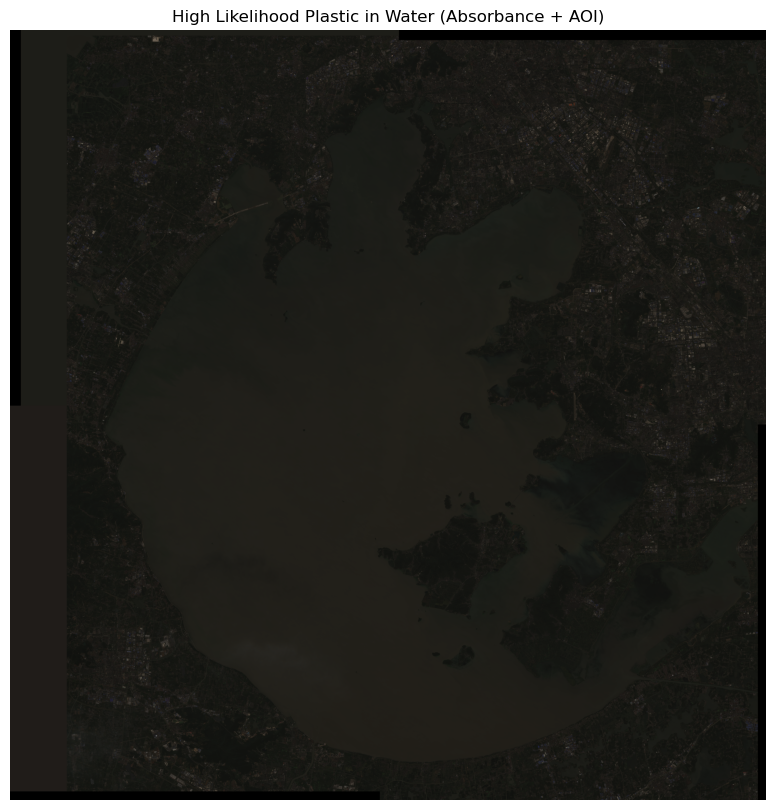

✅ 水环境高可能塑料已导出: mydata/simple_export_caculated/2022-10_best.tif.csv (共 0 点)
✅ 预览图已保存: mydata/simple_export_caculated/2022-10_best.tif.png


In [4]:
import os
import shutil


# 根目录
root_dir = "mydata/tif"
# 导出目录
export_dir = "mydata/simple_export_caculated"
os.makedirs(export_dir, exist_ok=True)

# 遍历一级日期目录
for file in os.listdir(root_dir):
    if file.lower().endswith(".tif"):
        src_path = os.path.join(root_dir, file)
        print(src_path)
        export_path=os.path.join(export_dir, file)
        plot_sateline(input_tif=src_path,
                      shp_file="mydata/shp/taihu.shp",
                      output_csv=f"{export_path}.csv",
                      preview_png=f"{export_path}.png")

In [ ]:
import rasterio
import numpy as np
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point
from rasterio.features import shapes
import cv2
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from tqdm import tqdm
import gc

# ===================== 工具函数 =====================


def resize_to_reference(arr, ref_shape):
    """将数组 arr 重采样到 ref_shape (height, width)，支持 bool 数组"""
    is_bool = arr.dtype == bool
    arr_uint8 = arr.astype(np.uint8) if is_bool else arr
    resized = cv2.resize(
        arr_uint8, (ref_shape[1], ref_shape[0]), interpolation=cv2.INTER_NEAREST)
    return resized.astype(bool) if is_bool else resized


def read_bands(file_path, band_indices):
    """读取多波段影像"""
    with rasterio.open(file_path) as src:
        bands = []
        for b in tqdm(band_indices, desc="Reading bands"):
            bands.append(src.read(b))
        return np.stack(bands, axis=-1), src.transform


def compute_ndwi(green, nir):
    return (green - nir) / (green + nir + 1e-10)


def compute_fdi(red, nir, swir):
    λred, λnir, λswir = 665, 842, 1610
    baseline = red + (swir - red) * (λnir - λred) / (λswir - λred)
    return nir - baseline

# ===================== 随机森林 =====================


def train_rf_model(X, y, n_estimators=200, max_depth=15):
    clf = RandomForestClassifier(
        n_estimators=n_estimators, max_depth=max_depth, random_state=42, n_jobs=-1)
    clf.fit(X, y)
    return clf


def predict_rf(clf, bands, chunk_size=1000):
    """优化后的 RF 预测函数，按更小的块处理"""
    h, w, c = bands.shape
    proba = np.zeros(h * w, dtype=np.float32)
    total_pixels = h * w
    for i in tqdm(range(0, total_pixels, chunk_size), desc="RF prediction"):
        end = min(i + chunk_size, total_pixels)
        X_chunk = bands.reshape(-1, c)[i:end]
        proba[i:end] = clf.predict_proba(X_chunk)[:, 1]
        del X_chunk  # 释放内存
        gc.collect()  # 强制垃圾回收
    return proba.reshape(h, w)

# ===================== UNet =====================


class FloatingDataset(Dataset):
    def __init__(self, images, masks):
        self.images = images
        self.masks = masks

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        return torch.FloatTensor(self.images[idx]).permute(2, 0, 1), torch.FloatTensor(self.masks[idx])[None, :, :]


class UNet(nn.Module):
    def __init__(self, in_channels=10, out_channels=1):
        super().__init__()
        self.enc1 = nn.Sequential(nn.Conv2d(in_channels, 32, 3, padding=1), nn.ReLU(
        ), nn.Conv2d(32, 32, 3, padding=1), nn.ReLU())
        self.pool = nn.MaxPool2d(2)
        self.enc2 = nn.Sequential(nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(
        ), nn.Conv2d(64, 64, 3, padding=1), nn.ReLU())
        self.up = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec1 = nn.Sequential(nn.Conv2d(64, 32, 3, padding=1), nn.ReLU(
        ), nn.Conv2d(32, 32, 3, padding=1), nn.ReLU())
        self.outc = nn.Conv2d(32, out_channels, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        u1 = self.up(e2)
        d1 = self.dec1(torch.cat([u1, e1], dim=1))
        return torch.sigmoid(self.outc(d1))

# ===================== 矢量化 =====================


def mask_to_vector(mask, transform):
    results = []
    for shape, value in shapes(mask.astype(np.uint8), transform=transform):
        if value == 1:
            results.append(Point(shape['coordinates'][0][0]))
    return gpd.GeoDataFrame(geometry=results)

# ===================== 可视化 =====================


def visualize_results(rgb, rf_mask, unet_mask, final_mask, points, stats, output_png):
    fig, axes = plt.subplots(2, 2, figsize=(20, 20))

    axes[0, 0].imshow(rgb)
    if len(points) > 0:
        axes[0, 0].scatter(points['col'], points['row'], s=5,
                           c='orange', label='Detected Points')
    axes[0, 0].set_title(
        f"RGB Image with Detected Points ({len(points)} points)")
    axes[0, 0].axis('off')
    axes[0, 0].legend()

    im = axes[0, 1].imshow(rf_mask, cmap='Reds', vmin=0, vmax=1)
    plt.colorbar(im, ax=axes[0, 1], label='Probability')
    axes[0, 1].set_title("Random Forest Probability Map")
    axes[0, 1].axis('off')

    im = axes[1, 0].imshow(unet_mask, cmap='Reds', vmin=0, vmax=1)
    plt.colorbar(im, ax=axes[1, 0], label='Probability')
    axes[1, 0].set_title("UNet Probability Map")
    axes[1, 0].axis('off')

    im = axes[1, 1].imshow(final_mask, cmap='Reds')
    plt.colorbar(im, ax=axes[1, 1], label='Binary Mask')
    axes[1, 1].set_title(
        f"Final Binary Mask\nArea: {stats['area_m2']:.2f} m², Pixels: {stats['pixel_count']}")
    axes[1, 1].axis('off')

    plt.tight_layout()
    plt.savefig(output_png, dpi=200, bbox_inches='tight')
    plt.show()
    plt.close()

# ===================== 统计信息 =====================


def compute_stats(binary_mask, pixel_area=10*10):
    area = np.sum(binary_mask) * pixel_area
    count = np.sum(binary_mask)
    return {"area_m2": area, "pixel_count": count}

# ===================== 漂浮物主流程 =====================


def floating_debris_detection(
    input_tif, mask_tif, shp_file, output_csv, preview_png,
    band_order=["B2", "B3", "B4", "B8", "B8A", "B11", "B12"],
    ndvi_thresh=0.1, absorbance_thresh=0.8, fdi_std_factor=1.5, rf_proba_thresh=0.7, unet_proba_thresh=0.7
):
    # 读取 shapefile
    with tqdm(total=1, desc="Reading shapefile") as pbar:
        gdf = gpd.read_file(shp_file)
        gdf = gdf.to_crs(rasterio.open(input_tif).crs)
        aoi_geometry = gdf.geometry.union_all()  # 修复 deprecation warning
        pbar.update(1)

    # 波段索引
    band_indices = [band_order.index(
        b) + 1 for b in ["B2", "B3", "B4", "B8", "B11", "B12"]]

    # 读取波段
    bands, transform = read_bands(input_tif, band_indices)

    # 波段处理
    with tqdm(total=6, desc="Processing bands") as pbar:
        B2, B3, B4, B8, B11, B12 = [bands[:, :, i].astype(
            np.float32) * 0.0001 for i in range(6)]
        pbar.update(6)

    # 计算 NDWI 和水体掩膜
    with tqdm(total=1, desc="Computing NDWI") as pbar:
        ndwi = compute_ndwi(B3, B8)
        water_mask = ndwi > 0
        pbar.update(1)

    # 计算 NDVI 和 FDI
    with tqdm(total=2, desc="Computing NDVI and FDI") as pbar:
        ndvi = (B8 - B4) / (B8 + B4 + 1e-6)
        pbar.update(1)
        fdi = compute_fdi(B4, B8, B11)
        fdi_thresh = np.nanmean(fdi[water_mask]) + \
            fdi_std_factor * np.nanstd(fdi[water_mask])
        pbar.update(1)

    # 计算吸光率
    with tqdm(total=2, desc="Computing absorbance") as pbar:
        B11[B11 <= 0] = np.nan
        B12[B12 <= 0] = np.nan
        A_B11 = -np.log10(B11)
        A_B12 = -np.log10(B12)
        absorb_mask = (A_B11 > absorbance_thresh) & (A_B12 > absorbance_thresh)
        pbar.update(2)

    # 读取掩膜
    with tqdm(total=1, desc="Reading mask") as pbar:
        with rasterio.open(mask_tif) as msk:
            mask = msk.read(1)
        pbar.update(1)

    # 重采样到一致尺寸
    ref_shape = water_mask.shape
    with tqdm(total=4, desc="Resizing arrays") as pbar:
        mask = resize_to_reference(mask, ref_shape)
        pbar.update(1)
        ndvi = resize_to_reference(ndvi, ref_shape)
        pbar.update(1)
        fdi = resize_to_reference(fdi, ref_shape)
        pbar.update(1)
        absorb_mask = resize_to_reference(absorb_mask, ref_shape)
        pbar.update(1)

    # 初始规则筛选
    water_plastic_mask = water_mask & (mask == 1) & (
        ndvi < ndvi_thresh) & (fdi > fdi_thresh) & absorb_mask

    # 准备机器学习输入
    with tqdm(total=1, desc="Preparing ML features") as pbar:
        features = np.stack(
            [B2, B3, B4, B8, B11, B12, ndvi, fdi, A_B11, A_B12], axis=-1)
        h, w, c = features.shape
        X = features.reshape(-1, c)
        y = mask.flatten()
        pbar.update(1)

    # 随机森林训练与预测
    with tqdm(total=2, desc="Random Forest") as pbar:
        X_train, _, y_train, _ = train_test_split(
            X, y, test_size=0.3, random_state=42)
        rf_clf = train_rf_model(X_train, y_train)
        pbar.update(1)
        rf_proba = predict_rf(
            rf_clf, features, chunk_size=1000)  # 减小 chunk_size
        rf_mask = rf_proba > rf_proba_thresh
        pbar.update(1)
        del X, X_train, y, y_train  # 释放内存
        gc.collect()

    # UNet 训练与预测
    dataset = FloatingDataset([features], [mask])
    dataloader = DataLoader(dataset, batch_size=1, shuffle=False)
    unet = UNet(in_channels=10)
    unet.to(device)  # 显式指定 mps 设备
    optimizer = torch.optim.Adam(unet.parameters(), lr=0.001)
    criterion = nn.BCELoss()

    # UNet 训练
    unet.train()
    for epoch in tqdm(range(5), desc="Training UNet"):
        for images, masks in dataloader:
            images, masks = images.to(device), masks.to(device)
            optimizer.zero_grad()
            outputs = unet(images)
            loss = criterion(outputs, masks)
            loss.backward()
            optimizer.step()

    # UNet 预测
    unet.eval()
    with torch.no_grad():
        unet_proba = unet(torch.FloatTensor(features).permute(2, 0, 1)[
                          None, :, :, :].to(device)).cpu().squeeze().numpy()
    unet_mask = unet_proba > unet_proba_thresh
    del features  # 释放内存
    gc.collect()

    # 融合规则和机器学习结果
    final_mask = water_plastic_mask & rf_mask & unet_mask

    # 获取候选点
    records = []
    rows, cols = np.where(final_mask)
    xs, ys = rasterio.transform.xy(transform, rows, cols)
    for r, c, x, y in tqdm(zip(rows, cols, xs, ys), total=len(rows), desc="Extracting candidate points"):
        point = Point(x, y)
        if point.within(aoi_geometry):
            records.append({
                "row": int(r), "col": int(c), "x": float(x), "y": float(y),
                "NDVI": float(ndvi[r, c]), "FDI": float(fdi[r, c]),
                "A_B11": float(A_B11[r, c]), "A_B12": float(A_B12[r, c]),
                "RF_Proba": float(rf_proba[r, c]), "UNet_Proba": float(unet_proba[r, c])
            })

    # 保存 CSV
    with tqdm(total=1, desc="Saving CSV") as pbar:
        df = pd.DataFrame(records)
        df.to_csv(output_csv, index=False, encoding="utf-8-sig")
        pbar.update(1)

    # 计算统计信息
    stats = compute_stats(final_mask)

    # 可视化
    rgb = np.dstack([np.clip(B4/np.nanmax(B4), 0, 1),
                     np.clip(B3/np.nanmax(B3), 0, 1),
                     np.clip(B2/np.nanmax(B2), 0, 1)])
    visualize_results(rgb, rf_proba, unet_proba,
                      final_mask, df, stats, preview_png)

    print(f"✅ CSV导出完成: {output_csv} ({len(df)} 点)")
    print(f"✅ 预览图保存完成: {preview_png}")
    print(f"✅ 统计信息: 面积 {stats['area_m2']:.2f} m², 像素数 {stats['pixel_count']}")
    return df


# 调用主函数
if __name__ == "__main__":
    df = floating_debris_detection(
        input_tif="Sentinel2_merged1.tif",
        mask_tif="plastic_mask.tif",
        shp_file="数据/taihu.shp",
        output_csv="plastic_candidates_water_filtered_absorbance.csv",
        preview_png="plastic_water_filtered_absorbance.png"
    )

Reading shapefile:   0%|          | 0/1 [00:01<?, ?it/s]


RasterioIOError: Sentinel2_merged1.tif: No such file or directory

In [3]:
import rasterio
import numpy as np
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point
from rasterio.features import shapes, rasterize
import cv2
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from tqdm import tqdm
import gc

# ===================== 工具函数 =====================

def filter_gdf(gdf, filter_field=None, filter_values=None, filter_query=None, filter_indices=None):
    """根据字段、查询表达式或索引筛选 shapefile 要素"""
    if filter_query:
        gdf = gdf.query(filter_query)
    if filter_field is not None and filter_values is not None:
        if filter_field not in gdf.columns:
            raise KeyError(f"字段 {filter_field} 不在 shapefile 属性中: {list(gdf.columns)}")
        if not isinstance(filter_values, (list, tuple, set, np.ndarray, pd.Series)):
            filter_values = [filter_values]
        gdf = gdf[gdf[filter_field].isin(filter_values)]
    if filter_indices is not None:
        if isinstance(filter_indices, (int, np.integer)):
            filter_indices = [int(filter_indices)]
        gdf = gdf.iloc[list(filter_indices)]
    gdf = gdf[gdf.geometry.notnull()]
    if gdf.empty:
        raise ValueError("筛选后的 shapefile 为空，请检查筛选条件。")
    return gdf



def resize_to_reference(arr, ref_shape):
    """将数组 arr 重采样到 ref_shape (height, width)，支持 bool 数组"""
    is_bool = arr.dtype == bool
    arr_uint8 = arr.astype(np.uint8) if is_bool else arr
    resized = cv2.resize(
        arr_uint8, (ref_shape[1], ref_shape[0]), interpolation=cv2.INTER_NEAREST)
    return resized.astype(bool) if is_bool else resized


def read_bands(file_path, band_indices):
    """读取多波段影像"""
    with rasterio.open(file_path) as src:
        bands = []
        for b in tqdm(band_indices, desc="Reading bands"):
            bands.append(src.read(b))
        return np.stack(bands, axis=-1), src.transform, src.meta


def compute_ndwi(green, nir):
    return (green - nir) / (green + nir + 1e-10)


def compute_fdi(red, nir, swir):
    λred, λnir, λswir = 665, 842, 1610
    baseline = red + (swir - red) * (λnir - λred) / (λswir - λred)
    return nir - baseline

# ===================== 随机森林 =====================


def train_rf_model(X, y, n_estimators=200, max_depth=15):
    clf = RandomForestClassifier(
        n_estimators=n_estimators, max_depth=max_depth, random_state=42, n_jobs=-1)
    clf.fit(X, y)
    return clf


# def predict_rf(clf, X, chunk_size=1000):
#     """优化后的 RF 预测函数，处理 2D 输入"""
#     n_samples, _ = X.shape
#     proba = np.zeros(n_samples, dtype=np.float32)
#     for i in tqdm(range(0, n_samples, chunk_size), desc="RF prediction"):
#         end = min(i + chunk_size, n_samples)
#         X_chunk = X[i:end]
#         proba[i:end] = clf.predict_proba(X_chunk)[:, 1]
#         del X_chunk
#         gc.collect()
#     return proba


def predict_rf(clf, X, chunk_size=1000):
    """优化后的 RF 预测函数，处理 2D 输入"""
    n_samples, _ = X.shape
    proba = np.zeros(n_samples, dtype=np.float32)
    for i in tqdm(range(0, n_samples, chunk_size), desc="RF prediction"):
        end = min(i + chunk_size, n_samples)
        X_chunk = X[i:end]
        probas = clf.predict_proba(X_chunk)
        if probas.shape[1] == 1:  # 只有一个类别
            proba[i:end] = probas[:, 0]  # 全部是该类别概率
        else:
            proba[i:end] = probas[:, 1]  # 正常二分类
        del X_chunk
        gc.collect()
    return proba
# ===================== UNet =====================


class FloatingDataset(Dataset):
    def __init__(self, images, masks):
        self.images = images
        self.masks = masks

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        return torch.FloatTensor(self.images[idx]).permute(2, 0, 1), torch.FloatTensor(self.masks[idx])[None, :, :]


class UNet(nn.Module):
    def __init__(self, in_channels=10, out_channels=1):
        super().__init__()
        self.enc1 = nn.Sequential(nn.Conv2d(in_channels, 32, 3, padding=1), nn.ReLU(
        ), nn.Conv2d(32, 32, 3, padding=1), nn.ReLU())
        self.pool = nn.MaxPool2d(2)
        self.enc2 = nn.Sequential(nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(
        ), nn.Conv2d(64, 64, 3, padding=1), nn.ReLU())
        self.up = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec1 = nn.Sequential(nn.Conv2d(64, 32, 3, padding=1), nn.ReLU(
        ), nn.Conv2d(32, 32, 3, padding=1), nn.ReLU())
        self.outc = nn.Conv2d(32, out_channels, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        u1 = self.up(e2)
        d1 = self.dec1(torch.cat([u1, e1], dim=1))
        return torch.sigmoid(self.outc(d1))

# ===================== 矢量化 =====================


def mask_to_vector(mask, transform):
    results = []
    for shape, value in shapes(mask.astype(np.uint8), transform=transform):
        if value == 1:
            results.append(Point(shape['coordinates'][0][0]))
    return gpd.GeoDataFrame(geometry=results)

# ===================== 可视化 =====================


def visualize_results(rgb, rf_mask, unet_mask, final_mask, points, stats, output_png):
    fig, axes = plt.subplots(2, 2, figsize=(20, 20))

    axes[0, 0].imshow(rgb)
    if len(points) > 0:
        axes[0, 0].scatter(points['col'], points['row'], s=5,
                           c='orange', label='Detected Points')
    axes[0, 0].set_title(
        f"RGB Image with Detected Points ({len(points)} points)")
    axes[0, 0].axis('off')
    axes[0, 0].legend()

    im = axes[0, 1].imshow(rf_mask, cmap='Reds', vmin=0, vmax=1)
    plt.colorbar(im, ax=axes[0, 1], label='Probability')
    axes[0, 1].set_title("Random Forest Probability Map")
    axes[0, 1].axis('off')

    im = axes[1, 0].imshow(unet_mask, cmap='Reds', vmin=0, vmax=1)
    plt.colorbar(im, ax=axes[1, 0], label='Probability')
    axes[1, 0].set_title("UNet Probability Map")
    axes[1, 0].axis('off')

    im = axes[1, 1].imshow(final_mask, cmap='Reds')
    plt.colorbar(im, ax=axes[1, 1], label='Binary Mask')
    axes[1, 1].set_title(
        f"Final Binary Mask\nArea: {stats['area_m2']:.2f} m², Pixels: {stats['pixel_count']}")
    axes[1, 1].axis('off')

    plt.tight_layout()
    plt.savefig(output_png, dpi=200, bbox_inches='tight')
    plt.show()
    plt.close()

# ===================== 统计信息 =====================


def compute_stats(binary_mask, pixel_area=10*10):
    area = np.sum(binary_mask) * pixel_area
    count = np.sum(binary_mask)
    return {"area_m2": area, "pixel_count": count}

# ===================== 漂浮物主流程 =====================


def floating_debris_detection(
    input_tif,
    mask_tif,
    shp_file,
    output_csv,
    preview_png,
    band_order=["B2", "B3", "B4", "B8", "B8A", "B11", "B12"],
    ndvi_thresh=0.1,
    absorbance_thresh=0.8,
    fdi_std_factor=1.5,
    rf_proba_thresh=0.7,
    unet_proba_thresh=0.7,
    filter_field=None,
    filter_values=None,
    filter_query=None,
    filter_indices=None,
):
    # 读取 shapefile
    with tqdm(total=1, desc="Reading shapefile") as pbar:
        gdf = gpd.read_file(shp_file)
        gdf = filter_gdf(gdf, filter_field, filter_values, filter_query, filter_indices)
        with rasterio.open(input_tif) as src_ref:
            gdf = gdf.to_crs(src_ref.crs)
        try:
            aoi_geometry = gdf.geometry.union_all()
        except AttributeError:
            aoi_geometry = gdf.geometry.unary_union
        pbar.update(1)

    # 波段索引
    band_indices = [band_order.index(
        b) + 1 for b in ["B2", "B3", "B4", "B8", "B11", "B12"]]

    # 读取波段
    bands, transform, meta = read_bands(input_tif, band_indices)

    # 创建 shapefile 掩膜
    with tqdm(total=1, desc="Creating shapefile mask") as pbar:
        shp_mask = rasterize(
            [(geom, 1) for geom in gdf.geometry],
            out_shape=(bands.shape[0], bands.shape[1]),
            transform=transform,
            fill=0,
            dtype=np.uint8
        ).astype(bool)
        pbar.update(1)

    # 波段处理
    with tqdm(total=6, desc="Processing bands") as pbar:
        B2, B3, B4, B8, B11, B12 = [bands[:, :, i].astype(
            np.float32) * 0.0001 for i in range(6)]
        pbar.update(6)

    # 应用 shapefile 掩膜
    B2[~shp_mask] = np.nan
    B3[~shp_mask] = np.nan
    B4[~shp_mask] = np.nan
    B8[~shp_mask] = np.nan
    B11[~shp_mask] = np.nan
    B12[~shp_mask] = np.nan

    # 计算 NDWI 和水体掩膜
    with tqdm(total=1, desc="Computing NDWI") as pbar:
        ndwi = compute_ndwi(B3, B8)
        water_mask = (ndwi > 0) & shp_mask
        pbar.update(1)

    # 计算 NDVI 和 FDI
    with tqdm(total=2, desc="Computing NDVI and FDI") as pbar:
        ndvi = (B8 - B4) / (B8 + B4 + 1e-6)
        ndvi[~shp_mask] = np.nan
        pbar.update(1)
        fdi = compute_fdi(B4, B8, B11)
        fdi[~shp_mask] = np.nan
        fdi_thresh = np.nanmean(fdi[water_mask]) + \
            fdi_std_factor * np.nanstd(fdi[water_mask])
        pbar.update(1)

    # 计算吸光率
    with tqdm(total=2, desc="Computing absorbance") as pbar:
        B11[B11 <= 0] = np.nan
        B12[B12 <= 0] = np.nan
        A_B11 = -np.log10(B11)
        A_B12 = -np.log10(B12)
        A_B11[~shp_mask] = np.nan
        A_B12[~shp_mask] = np.nan
        absorb_mask = (A_B11 > absorbance_thresh) & (
            A_B12 > absorbance_thresh) & shp_mask
        pbar.update(2)

    # 读取掩膜
    with tqdm(total=1, desc="Reading mask") as pbar:
        with rasterio.open(mask_tif) as msk:
            mask = msk.read(1)
        pbar.update(1)

    # 重采样到一致尺寸
    ref_shape = water_mask.shape
    with tqdm(total=1, desc="Resizing mask") as pbar:
        mask = resize_to_reference(mask, ref_shape)
        mask[~shp_mask] = 0
        pbar.update(1)

    # 初始规则筛选
    water_plastic_mask = water_mask & (mask == 1) & (
        ndvi < ndvi_thresh) & (fdi > fdi_thresh) & absorb_mask

    # 准备机器学习输入
    with tqdm(total=1, desc="Preparing ML features") as pbar:
        features = np.stack(
            [B2, B3, B4, B8, B11, B12, ndvi, fdi, A_B11, A_B12], axis=-1)
        features[~shp_mask] = np.nan
        h, w, c = features.shape
        valid_pixels = shp_mask.flatten()
        X = features.reshape(-1, c)[valid_pixels]
        y = mask.flatten()[valid_pixels]
        pbar.update(1)

    # 随机森林训练与预测
    with tqdm(total=2, desc="Random Forest") as pbar:
        X_train, _, y_train, _ = train_test_split(
            X, y, test_size=0.3, random_state=42)
        rf_clf = train_rf_model(X_train, y_train)
        pbar.update(1)
        rf_proba = np.zeros(h * w, dtype=np.float32)
        rf_proba[valid_pixels] = predict_rf(
            rf_clf, X, chunk_size=1000)  # 直接使用 2D X
        rf_proba = rf_proba.reshape(h, w)
        rf_mask = (rf_proba > rf_proba_thresh) & shp_mask
        pbar.update(1)
        del X, X_train, y, y_train
        gc.collect()

    # UNet 训练与预测
    dataset = FloatingDataset([features], [mask])
    dataloader = DataLoader(dataset, batch_size=1, shuffle=False)
    unet = UNet(in_channels=10)
    unet.to(device)
    optimizer = torch.optim.Adam(unet.parameters(), lr=0.001)
    criterion = nn.BCELoss()

    # UNet 训练
    unet.train()
    for epoch in tqdm(range(5), desc="Training UNet"):
        for images, masks in dataloader:
            images, masks = images.to(device), masks.to(device)
            optimizer.zero_grad()
            outputs = unet(images)
            loss = criterion(outputs, masks)
            loss.backward()
            optimizer.step()

    # UNet 预测
    unet.eval()
    with torch.no_grad():
        unet_proba = unet(torch.FloatTensor(features).permute(2, 0, 1)[
                          None, :, :, :].to(device)).cpu().squeeze().numpy()
    unet_mask = (unet_proba > unet_proba_thresh) & shp_mask
    del features
    gc.collect()

    # 融合规则和机器学习结果
    final_mask = water_plastic_mask & rf_mask & unet_mask

    # 获取候选点
    records = []
    rows, cols = np.where(final_mask)
    xs, ys = rasterio.transform.xy(transform, rows, cols)
    for r, c, x, y in tqdm(zip(rows, cols, xs, ys), total=len(rows), desc="Extracting candidate points"):
        records.append({
            "row": int(r), "col": int(c), "x": float(x), "y": float(y),
            "NDVI": float(ndvi[r, c]) if not np.isnan(ndvi[r, c]) else np.nan,
            "FDI": float(fdi[r, c]) if not np.isnan(fdi[r, c]) else np.nan,
            "A_B11": float(A_B11[r, c]) if not np.isnan(A_B11[r, c]) else np.nan,
            "A_B12": float(A_B12[r, c]) if not np.isnan(A_B12[r, c]) else np.nan,
            "RF_Proba": float(rf_proba[r, c]) if not np.isnan(rf_proba[r, c]) else np.nan,
            "UNet_Proba": float(unet_proba[r, c]) if not np.isnan(unet_proba[r, c]) else np.nan
        })

    # 保存 CSV
    with tqdm(total=1, desc="Saving CSV") as pbar:
        df = pd.DataFrame(records)
        df.to_csv(output_csv, index=False, encoding="utf-8-sig")
        pbar.update(1)

    # 计算统计信息
    stats = compute_stats(final_mask)

    # 可视化
    rgb = np.dstack([np.clip(B4/np.nanmax(B4, where=shp_mask, initial=1), 0, 1),
                     np.clip(B3/np.nanmax(B3, where=shp_mask, initial=1), 0, 1),
                     np.clip(B2/np.nanmax(B2, where=shp_mask, initial=1), 0, 1)])
    visualize_results(rgb, rf_proba, unet_mask,
                      final_mask, df, stats, preview_png)

    print(f"✅ CSV导出完成: {output_csv} ({len(df)} 点)")
    print(f"✅ 预览图保存完成: {preview_png}")
    print(f"✅ 统计信息: 面积 {stats['area_m2']:.2f} m², 像素数 {stats['pixel_count']}")
    return df



def create_mask_tif_from_shp(
    shp_file,
    reference_tif,
    output_mask_tif,
    filter_field=None,
    filter_values=None,
    filter_query=None,
    filter_indices=None,
):
    """根据 shapefile 生成与 reference_tif 对齐的 mask tif"""
    with rasterio.open(reference_tif) as src:
        meta = src.meta.copy()
        transform = src.transform
        out_shape = (src.height, src.width)
        target_crs = src.crs

    # 读取 shapefile
    gdf = gpd.read_file(shp_file)
    gdf = filter_gdf(gdf, filter_field, filter_values, filter_query, filter_indices)
    gdf = gdf.to_crs(target_crs)

    # 栅格化
    mask = rasterize(
        [(geom, 1) for geom in gdf.geometry],
        out_shape=out_shape,
        transform=transform,
        fill=0,
        dtype=np.uint8
    )

    # 保存为 GeoTIFF
    meta.update(dtype=rasterio.uint8, count=1, compress="lzw")
    with rasterio.open(output_mask_tif, "w", **meta) as dst:
        dst.write(mask, 1)

    print(f"✅ 掩膜文件已生成: {output_mask_tif}")
    return output_mask_tif

# 调用主函数
if __name__ == "__main__":
    input_tif = "export_tifs_from_merged/2022-01-31_2022-02-27_02-49-04.tif"
    shp_file = "数据/taihu.shp"
    mask_tif = "plastic_mask.tif"
    device='cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu'

    # 可选: 只针对 shapefile 中指定要素进行处理
    shapefile_kwargs = {
        # "filter_field": "NAME",
        # "filter_values": ["目标区域"],
        # "filter_query": "type == 'lake'",
        # "filter_indices": [0, 2],
    }

    # 如果 mask 文件不存在，自动生成
    import os
    if not os.path.exists(mask_tif):
        create_mask_tif_from_shp(
            shp_file, input_tif, mask_tif, **shapefile_kwargs
        )

    df = floating_debris_detection(
        input_tif=input_tif,
        mask_tif=mask_tif,
        shp_file=shp_file,
        output_csv="plastic_candidates_water_filtered_absorbance.csv",
        preview_png="plastic_water_filtered_absorbance.png",
        **shapefile_kwargs
    )


Training UNet:   0%|          | 0/5 [02:56<?, ?it/s]


RuntimeError: Sizes of tensors must match except in dimension 1. Expected size 7818 but got size 7819 for tensor number 1 in the list.